# Classificação com Random Forest em Python (Scikit-Learn)

Este notebook é uma adaptação, em português, do tutorial da DataCamp **["Random Forest Classification in Python With Scikit-Learn"](https://www.datacamp.com/tutorial/random-forests-classifier-python)**, de Adam Shafi.

Vamos aprender:

- Como as **Random Forests** funcionam como método de *ensemble learning* (aprendizado em conjunto);
- Como construir e treinar um classificador usando o **scikit-learn**;
- Como avaliar a performance do modelo com métricas comuns (acurácia, precisão, recall e matriz de confusão);
- Como ajustar hiperparâmetros com `RandomizedSearchCV`;
- Como visualizar árvores individuais e a importância das features.

> Pré-requisitos: noções básicas de Python, pandas e scikit-learn.

## O que são Random Forests?

Random Forest é um algoritmo popular de **aprendizado supervisionado** que pode ser usado tanto para regressão quanto para classificação. Principais características:

- É um método **supervisionado**: existe uma variável alvo (target) rotulada.
- Pode resolver problemas de **regressão** (alvo numérico) e de **classificação** (alvo categórico).
- É um método de **ensemble**: combina as previsões de vários modelos menores.
- Cada um desses modelos menores é uma **árvore de decisão**.

### Como funciona a classificação por Random Forest

Imagine que você tem um problema complexo e reúne um grupo de especialistas de diferentes áreas para opinar. Cada especialista dá sua opinião com base em sua experiência, e no final todos votam para chegar a uma decisão final.

Em uma Random Forest, várias árvores de decisão são criadas usando **subconjuntos aleatórios diferentes dos dados e das features**. Cada árvore é como um especialista, dando sua própria "opinião" sobre como classificar os dados. A previsão final é feita calculando a previsão de cada árvore e escolhendo o resultado mais votado (para regressão, usa-se uma média em vez de votação).

## Sobre o dataset

Vamos usar o dataset **Bank Marketing**, que contém dados de campanhas de marketing direto (por telefone) de uma instituição bancária portuguesa. O objetivo das campanhas era vender assinaturas de depósitos a prazo (term deposit).

Assim como no tutorial, vamos usar apenas 4 colunas de entrada:

- `age`: idade da pessoa que recebeu a ligação;
- `default`: se a pessoa está inadimplente (em default) no crédito;
- `cons.price.idx`: índice de preços ao consumidor no momento da ligação;
- `cons.conf.idx`: índice de confiança do consumidor no momento da ligação;

E a coluna alvo:

- `y`: se a pessoa assinou o depósito a prazo (o que queremos prever).

O dataset original está disponível no [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/222/bank+marketing). Para carregá-lo de forma simples e reprodutível no Colab, vamos usar o pacote `ucimlrepo`, mantido pelo próprio UCI.

## Instalação e importação dos pacotes

In [1]:
#Instala pacotes
!pip install -q ucimlrepo
!apt-get -qq install -y graphviz > /dev/null

In [2]:

import pandas as pd
import numpy as np


from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from scipy.stats import randint


from sklearn.tree import export_graphviz
from IPython.display import Image, display
import graphviz

# Obtenção do dataset
from ucimlrepo import fetch_ucirepo

## Carregando o dataset



Download do dataset: https://www.kaggle.com/datasets/sahistapatel96/bankadditionalfullcsv?resource=download

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
bank_data_full = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/bank-additional-full.csv",
    sep=";"
)

# Seleciona apenas as colunas usadas no tutorial
bank_data = bank_data_full[['age', 'default', 'cons.price.idx', 'cons.conf.idx', 'y']].copy()

bank_data.head()

,age,default,cons.price.idx,cons.conf.idx,y
0,56,no,93.994,-36.4,no
1,57,unknown,93.994,-36.4,no
2,37,no,93.994,-36.4,no
3,40,no,93.994,-36.4,no
4,56,no,93.994,-36.4,no


In [5]:
bank_data.info()
bank_data['default'].value_counts(dropna=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   default         41188 non-null  object 
 2   cons.price.idx  41188 non-null  float64
 3   cons.conf.idx   41188 non-null  float64
 4   y               41188 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 1.6+ MB


,count
default,
no,32588
unknown,8597
yes,3


## Pré-processamento dos dados

Modelos baseados em árvores (como a Random Forest) são muito mais robustos a outliers do que modelos lineares, e não precisam que as variáveis sejam normalizadas para funcionar bem. Por isso, precisamos fazer pouquíssimo pré-processamento:

- Mapear a coluna `default` (que contém `no` e `yes`) para `0` e `1`, respectivamente. Valores `unknown` serão tratados como `no` (0) neste exemplo.
- Mapear o alvo `y` para `1` (assinou) e `0` (não assinou).

In [6]:
bank_data['default'] = bank_data['default'].map({'no': 0, 'yes': 1, 'unknown': 0})
bank_data['y'] = bank_data['y'].map({'no': 0, 'yes': 1})

bank_data.head()

,age,default,cons.price.idx,cons.conf.idx,y
0,56,0,93.994,-36.4,0
1,57,0,93.994,-36.4,0
2,37,0,93.994,-36.4,0
3,40,0,93.994,-36.4,0
4,56,0,93.994,-36.4,0


## Dividindo os dados em treino e teste

Ao treinar qualquer modelo de aprendizado supervisionado, é importante dividir os dados em conjuntos de **treino** e **teste**:

- Os **dados de treino** são usados para ajustar (fit) o modelo — o algoritmo aprende a relação entre as features e o alvo.
- Os **dados de teste** são usados para avaliar a performance do modelo em dados que ele nunca viu.

O código abaixo separa as features (`X`) do alvo (`y`) e depois faz a divisão treino/teste.

In [7]:
# Divide os dados em features (X) e alvo (y)
X = bank_data.drop('y', axis=1)
y = bank_data['y']

# Divide em conjuntos de treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train.shape, X_test.shape

((32950, 4), (8238, 4))

## Treinando e avaliando o modelo Random Forest

Primeiro criamos uma instância do modelo Random Forest com os parâmetros padrão e o ajustamos (fit) aos dados de treino, passando tanto as features quanto o alvo para que o modelo possa aprender.

In [8]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

Agora que temos um modelo treinado, precisamos verificar se ele faz previsões precisas.

In [9]:
y_pred = rf.predict(X_test)

A forma mais simples de avaliar o modelo é pela **acurácia**: comparamos as previsões com os valores reais do conjunto de teste e contamos quantas o modelo acertou.

In [10]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8895362952172857


In [14]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.8895362952172857
Precision: 0.5211267605633803
Recall: 0.23922413793103448
F1 Score: 0.32791728212703103


Esse já é um resultado razoável! Mas talvez consigamos melhorar otimizando os hiperparâmetros.

> **Nota:** a acurácia sozinha pode enganar em dados desbalanceados (como é o caso aqui, já que a maioria das pessoas não assina o depósito). Sempre vale checar **precisão** e **recall** para entender o trade-off entre falsos positivos e falsos negativos.

## Visualizando os resultados

Podemos usar o código abaixo para visualizar as 3 primeiras árvores da floresta. Cada árvore é limitada a mostrar apenas os primeiros níveis (`max_depth=2`), já que árvores completas podem ficar enormes e difíceis de visualizar.

As cores representam a classe majoritária de cada nó: vermelho indica maioria da classe `0` (não assinou) e azul indica maioria da classe `1` (assinou). Quanto mais escura a cor, mais "pura" é a divisão. Cada nó também mostra:

1. A variável e o valor de corte usados na divisão;
2. A porcentagem do total de amostras naquele nó;
3. A proporção entre as classes naquele nó.

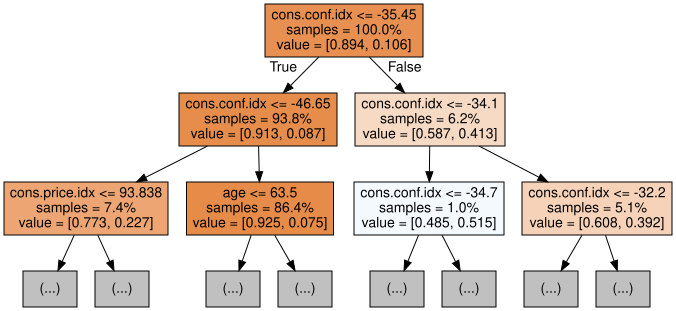

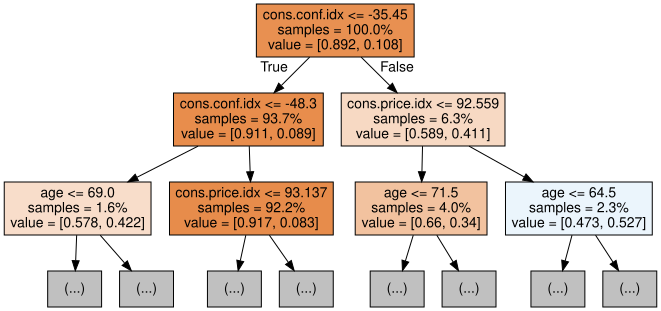

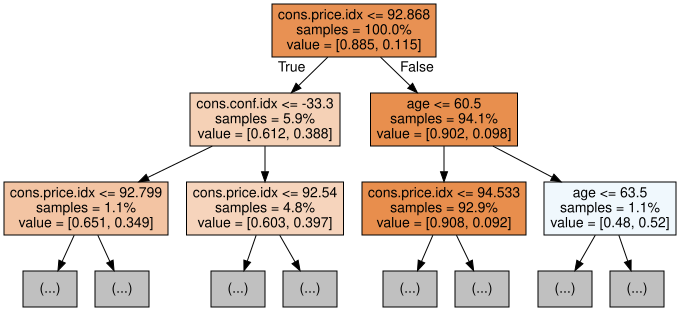

In [11]:
# Exporta e exibe as 3 primeiras árvores de decisão da floresta
for i in range(3):
    tree = rf.estimators_[i]
    dot_data = export_graphviz(
        tree,
        feature_names=X_train.columns,
        filled=True,
        max_depth=2,
        impurity=False,
        proportion=True,
    )
    graph = graphviz.Source(dot_data)
    display(graph)

## Ajuste de hiperparâmetros (Hyperparameter Tuning)

O código abaixo usa o `RandomizedSearchCV` do scikit-learn, que testa combinações aleatórias de hiperparâmetros dentro de um intervalo definido. Definimos os hiperparâmetros e seus intervalos no dicionário `param_dist`. Neste caso, usamos:

- **`n_estimators`**: número de árvores de decisão na floresta. Aumentar esse hiperparâmetro geralmente melhora a performance do modelo, mas também aumenta o custo computacional de treino e previsão.
- **`max_depth`**: profundidade máxima de cada árvore na floresta. Um valor muito alto pode levar a *overfitting*, enquanto um valor muito baixo pode levar a *underfitting*.
- **`min_samples_split`** e **`min_samples_leaf`**: controlam o número mínimo de amostras necessárias para dividir um nó ou formar uma folha, respectivamente — também ajudam a controlar o overfitting.

In [21]:
param_dist = {
    'n_estimators': randint(100, 500),
    'max_depth': randint(3, 15),
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 5),
}

# Cria um classificador Random Forest
rf = RandomForestClassifier(random_state=42, n_jobs=-1)

# Usa busca aleatória para encontrar os melhores hiperparâmetros
rand_search = RandomizedSearchCV(
    rf,
    param_distributions=param_dist,
    n_iter=10,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42,
)

rand_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
                   n_jobs=-1,
                   param_distributions={'max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7bbf512b52e0>,
                                        'min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7bbf5094f7d0>,
                                        'min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7bbf5094ed50>,
                                        'n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7bbf508dca50>},
                   random_state=42, scoring='f1')

O `RandomizedSearchCV` treina vários modelos (definidos por `n_iter`) e salva cada um. O código abaixo cria uma variável para o melhor modelo encontrado e imprime seus hiperparâmetros.

Como não passamos um sistema de pontuação (`scoring`) diferente, ele usa acurácia por padrão. A busca também usa **validação cruzada** (`cv=5`): os dados de treino são divididos em 5 grupos, e a cada rodada 4 grupos são usados para treinar e 1 para testar. Isso é repetido para cada grupo, e a acurácia final é a média entre as rodadas.

In [16]:
# Cria uma variável para o melhor modelo
best_rf = rand_search.best_estimator_

# Imprime os melhores hiperparâmetros encontrados
print('Best hyperparameters:', rand_search.best_params_)

Best hyperparameters: {'max_depth': 6, 'min_samples_leaf': 4, 'min_samples_split': 9, 'n_estimators': 230}


## Mais métricas de avaliação

### Matriz de confusão

A matriz de confusão mostra o que o modelo previu contra o que era o valor real. Ela ajuda a entender o trade-off entre **falsos positivos** (canto superior direito) e **falsos negativos** (canto inferior esquerdo).

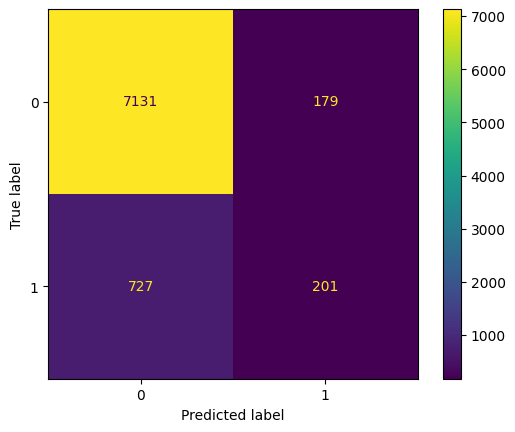

In [23]:
# Gera previsões com o melhor modelo
y_pred = best_rf.predict(X_test)

# Cria a matriz de confusão
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(confusion_matrix=cm).plot();

### Acurácia, precisão e recall

Vamos também avaliar o melhor modelo com acurácia, precisão e recall

In [24]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.8900218499635834
Precision: 0.5289473684210526
Recall: 0.2165948275862069
F1 Score: 0.3073394495412844


### Importância das features

O código abaixo plota a importância de cada feature, usando a pontuação interna do modelo para descobrir a melhor forma de dividir os dados dentro de cada árvore de decisão.

<Axes: >

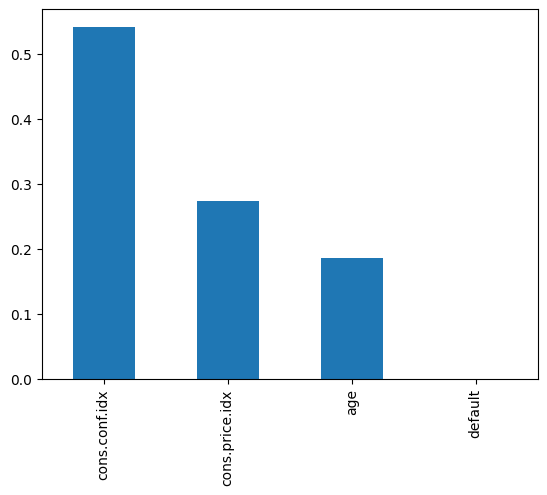

In [ ]:
# Cria uma série com as importâncias das features do modelo e os nomes das colunas de treino
importances = pd.Series(best_rf.feature_importances_, index=X_train.columns)
importances.sort_values(ascending=False).plot.bar()

Isso nos mostra que o **índice de confiança do consumidor** (`cons.conf.idx`) no momento da ligação foi o maior preditor de se a pessoa assinou ou não o depósito.

## Quando usar (e quando não usar) Random Forests

Random Forests são uma ótima escolha quando você precisa de um **baseline forte** que funciona bem "fora da caixa". Elas lidam bem com features numéricas e categóricas, toleram valores ausentes com mais facilidade e são menos propensas a overfitting do que uma única árvore de decisão.

**Use Random Forests quando:**

- Você tem **dados tabulares** com tipos de features mistos;
- Você quer um **modelo robusto** sem muito pré-processamento ou normalização;
- **Interpretabilidade** (via importância de features) importa para sua aplicação.

**Random Forests podem não ser ideais quando:**

- Você precisa de **previsões em tempo real** — podem ser mais lentas que modelos únicos;
- Você está lidando com **dados de altíssima dimensionalidade** (ex.: texto ou imagens);
- Você quer **acurácia de última geração** em dados estruturados, onde métodos de *gradient boosting* como **XGBoost** ou **LightGBM** costumam superá-las.

## Resumo

Neste notebook, seguimos o fluxo de trabalho de Machine Learning aplicado a uma Random Forest de classificação:

1. Carregamos e preparamos os dados (**feature engineering** mínimo, já que árvores lidam bem com dados "crus");
2. Dividimos os dados em treino e teste;
3. Treinamos um modelo baseline e avaliamos sua acurácia;
4. Visualizamos árvores individuais da floresta;
5. Fizemos **ajuste de hiperparâmetros** com `RandomizedSearchCV`;
6. Avaliamos o melhor modelo com matriz de confusão, precisão e recall;
7. Analisamos a **importância das features**.

Para aprofundar, o tutorial original recomenda os cursos [Supervised Learning with scikit-learn](https://www.datacamp.com/courses/supervised-learning-with-scikit-learn), [Machine Learning with Tree-Based Models in Python](https://www.datacamp.com/courses/machine-learning-with-tree-based-models-in-python) e [Ensemble Methods in Python](https://www.datacamp.com/courses/ensemble-methods-in-python) da DataCamp.